# Machine Learning for Next-Day Rain Prediction in Lund

> Author：Haoyang Qian, Ruowen Xiao
>
> Date: 2026/10/28

**Before this, first run `get_data.ipynb` to fetch training data named `./data/lund_daily_weather`.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score,
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

## 1. Data Preprocessing and Exploration

### 1.1. Data Loading and Exploration

In [2]:
sns.set_theme(style="whitegrid")
# ==============================================================================
# 1 Data Loading & Basic Exploration
# ==============================================================================
df_daily = pd.read_csv("./data/lund_daily_weather.csv")

print("Dataset Shape:", df_daily.shape)
print("\n--- First 5 rows ---")
display(df_daily.head())

print("\n--- Data Types and Missing Values ---")
df_daily.info()

Dataset Shape: (5477, 17)

--- First 5 rows ---


,date,temp_max,temp_min,temp_mean,humidity_mean,dewpoint_mean,pressure_mean,cloud_cover_mean,wind_speed_max,precipitation_today,temp_range,dewpoint_spread,pressure_change,precipitation_tomorrow,rain_tomorrow,month_sin,month_cos
0,2010-01-01,-4.7,-8.3,-6.741667,80.208333,-9.629167,996.700000,83.125000,14.1,0.0,3.6,2.887500,0.000000,0.0,0,0.5,0.866025
1,2010-01-02,-4.0,-9.5,-6.683333,78.291667,-9.900000,1007.425000,22.875000,19.4,0.0,5.5,3.216667,10.725000,0.0,0,0.5,0.866025
2,2010-01-03,-5.9,-11.5,-9.350000,75.791667,-12.862500,1013.662500,33.250000,11.3,0.0,5.6,3.512500,6.237500,1.4,1,0.5,0.866025
3,2010-01-04,-1.0,-6.1,-3.137500,86.541667,-5.079167,1004.058333,85.000000,24.3,1.4,5.1,1.941667,-9.604167,1.5,1,0.5,0.866025
4,2010-01-05,-0.7,-2.6,-1.825000,93.166667,-2.779167,999.670833,89.583333,13.4,1.5,1.9,0.954167,-4.387500,1.3,1,0.5,0.866025



--- Data Types and Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5477 entries, 0 to 5476
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    5477 non-null   object 
 1   temp_max                5477 non-null   float64
 2   temp_min                5477 non-null   float64
 3   temp_mean               5477 non-null   float64
 4   humidity_mean           5477 non-null   float64
 5   dewpoint_mean           5477 non-null   float64
 6   pressure_mean           5477 non-null   float64
 7   cloud_cover_mean        5477 non-null   float64
 8   wind_speed_max          5477 non-null   float64
 9   precipitation_today     5477 non-null   float64
 10  temp_range              5477 non-null   float64
 11  dewpoint_spread         5477 non-null   float64
 12  pressure_change         5477 non-null   float64
 13  precipitation_tomorrow  5477 non-null   float64
 14  r

In [3]:
print("Dataset shape:", df_daily.shape)
print("Date range:",
      df_daily["date"].min(),
      "to",
      df_daily["date"].max())

print("Duplicate dates:", df_daily["date"].duplicated().sum())

dates = pd.to_datetime(df_daily["date"]).sort_values()
date_gaps = (dates.diff().dropna().dt.days > 1).sum()
print("Date gaps:", date_gaps)

print("\nMissing values:")
print(df_daily.isna().sum())

print("\nRainTomorrow counts:")
print(df_daily["rain_tomorrow"].value_counts(dropna=False))

print("\nRainTomorrow proportions:")
print(df_daily["rain_tomorrow"].value_counts(normalize=True))

Dataset shape: (5477, 17)
Date range: 2010-01-01 to 2024-12-29
Duplicate dates: 0
Date gaps: 0

Missing values:
date                      0
temp_max                  0
temp_min                  0
temp_mean                 0
humidity_mean             0
dewpoint_mean             0
pressure_mean             0
cloud_cover_mean          0
wind_speed_max            0
precipitation_today       0
temp_range                0
dewpoint_spread           0
pressure_change           0
precipitation_tomorrow    0
rain_tomorrow             0
month_sin                 0
month_cos                 0
dtype: int64

RainTomorrow counts:
rain_tomorrow
1    3048
0    2429
Name: count, dtype: int64

RainTomorrow proportions:
rain_tomorrow
1    0.556509
0    0.443491
Name: proportion, dtype: float64


### 1.2. Descriptive Statistics

In [4]:
numeric_features = df_daily.select_dtypes(include="number").drop(
    columns=["rain_tomorrow"]
)

# Descriptive statistics
print("Descriptive Statistics:")
print(numeric_features.describe().T.round(2))

Descriptive Statistics:
                         count     mean    std     min      25%      50%  \
temp_max                5477.0    11.96   7.52  -10.00     6.10    11.80   
temp_min                5477.0     5.98   6.55  -18.00     1.30     6.10   
temp_mean               5477.0     8.99   6.90  -13.92     3.87     8.89   
humidity_mean           5477.0    80.37   9.73   45.42    73.38    81.25   
dewpoint_mean           5477.0     5.51   6.32  -17.28     1.26     5.58   
pressure_mean           5477.0  1007.17  10.01  966.18  1001.17  1007.73   
cloud_cover_mean        5477.0    67.35  26.83    0.00    49.46    72.92   
wind_speed_max          5477.0    22.30   7.92    5.20    16.60    21.40   
precipitation_today     5477.0     2.01   3.64    0.00     0.00     0.30   
temp_range              5477.0     5.98   2.95    0.50     3.70     5.50   
dewpoint_spread         5477.0     3.48   2.01    0.07     1.85     3.16   
pressure_change         5477.0     0.00   6.13  -28.94    -3.57 

### 1.3. Data Visualization

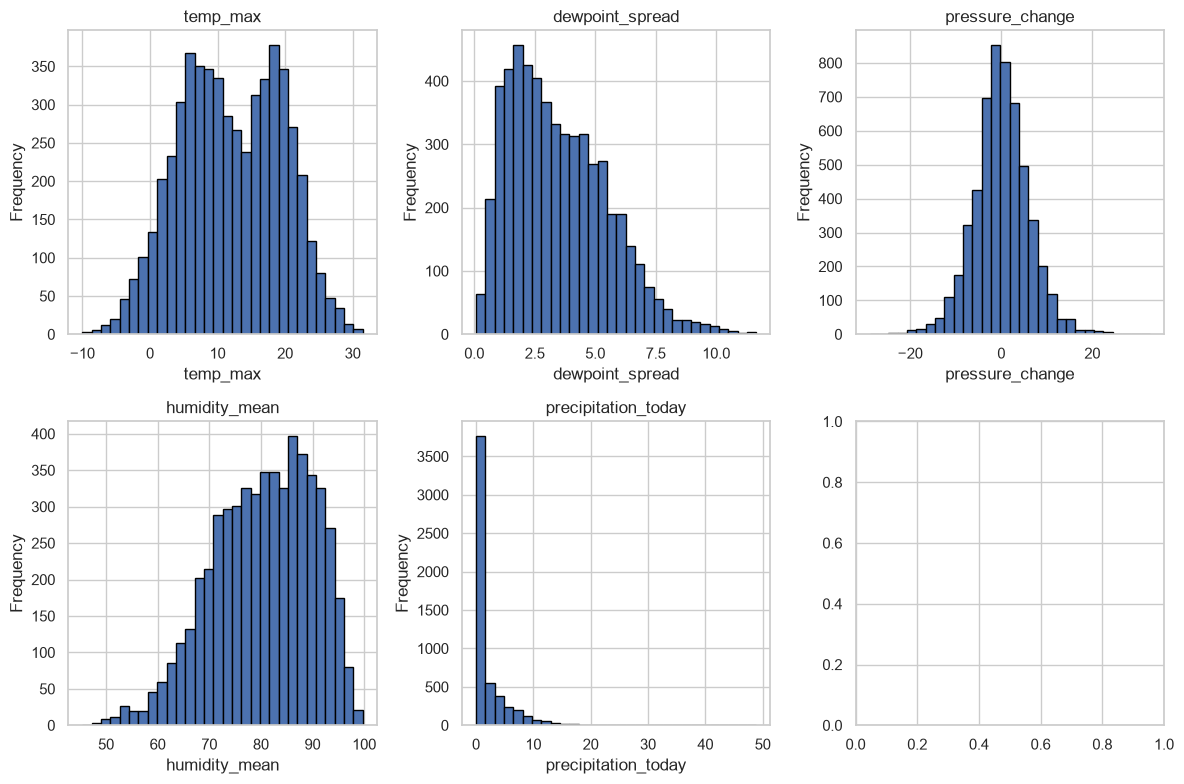

In [5]:
features_to_plot = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean",
    "precipitation_today"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, feature in zip(axes.flat, features_to_plot):
    ax.hist(df_daily[feature], bins=30, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [6]:
# 1. Check distribution skewness
features_to_check = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean",
    "precipitation_today",
    "wind_speed_max"
]

print("=== Distribution Skewness ===")
print(df_daily[features_to_check].skew().round(2))


# 2. Detect potential outliers using the IQR rule
print("\n=== Potential Outliers (IQR Rule) ===")

for col in features_to_check:
    q1 = df_daily[col].quantile(0.25)
    q3 = df_daily[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df_daily[
        (df_daily[col] < lower) |
        (df_daily[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} potential outliers "
        f"({len(outliers) / len(df_daily) * 100:.2f}%)"
    )


# 3. Explore the relationship between pressure and humidity
print("\n=== Pressure-Humidity Correlation ===")

print(
    "Pearson correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="pearson"
    ), 3)
)

print(
    "Spearman correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="spearman"
    ), 3)
)

=== Distribution Skewness ===
temp_max              -0.04
dewpoint_spread        0.71
pressure_change        0.06
humidity_mean         -0.43
precipitation_today    3.56
wind_speed_max         0.69
dtype: float64

=== Potential Outliers (IQR Rule) ===
temp_max: 0 potential outliers (0.00%)
dewpoint_spread: 49 potential outliers (0.89%)
pressure_change: 161 potential outliers (2.94%)
humidity_mean: 15 potential outliers (0.27%)
precipitation_today: 550 potential outliers (10.04%)
wind_speed_max: 80 potential outliers (1.46%)

=== Pressure-Humidity Correlation ===
Pearson correlation: -0.229
Spearman correlation: -0.218


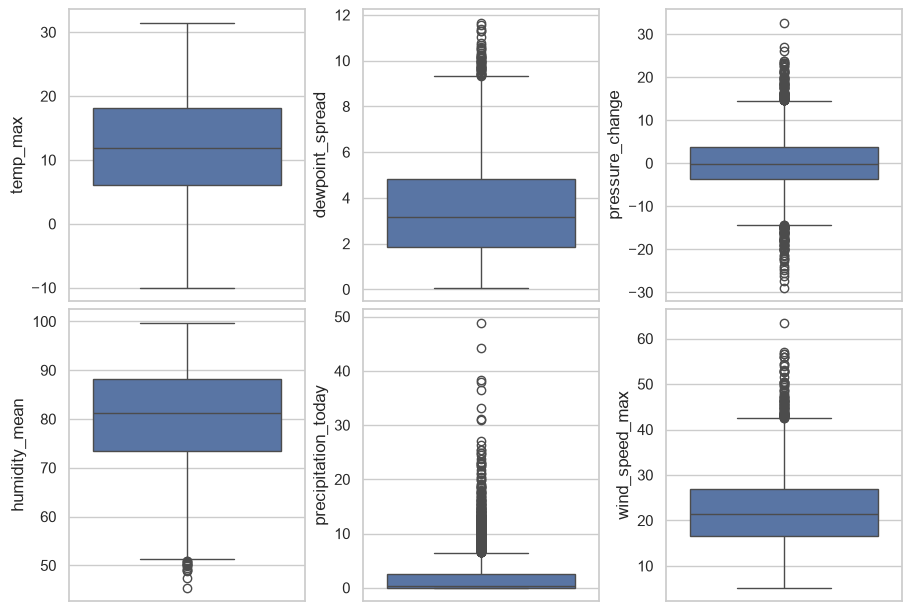

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6), constrained_layout=True)
axes = axes.flatten()
for i, col in enumerate(features_to_check):
    sns.boxplot(data=df_daily, y=col, ax=axes[i])

plt.show()

## 2. Unsupervised Learning - K-means Clustering

In [8]:
# 1. Copy the existing dataset and ensure chronological order
df_model = df_daily.copy()

df_model["date"] = pd.to_datetime(df_model["date"])
df_model = (
    df_model.sort_values("date")
    .reset_index(drop=True)
)

# 2. Select today's weather features
feature_cols = [
    "temp_max",
    "temp_min",
    "temp_mean",
    "humidity_mean",
    "dewpoint_mean",
    "pressure_mean",
    "cloud_cover_mean",
    "wind_speed_max",
    "precipitation_today",
    "temp_range",
    "dewpoint_spread",
    "pressure_change",
    "month_cos",
    "month_sin"
]

X = df_model[feature_cols]
y = df_model["rain_tomorrow"].astype(int)

# 3. Split: 70% / 15% / 15%
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# 4. Print date ranges and dataset sizes
print("=== Dataset Split ===")

for name, start, end, X_part, y_part in [
    ("Training", 0, train_end, X_train, y_train),
    ("Validation", train_end, val_end, X_val, y_val),
    ("Test", val_end, n, X_test, y_test)
]:
    print(f"\n{name} Set")
    print("Number of samples:", len(X_part))
    print(
        "Date range:",
        df_model["date"].iloc[start].date(),
        "to",
        df_model["date"].iloc[end - 1].date()
    )
    print("RainTomorrow proportions:")
    print(y_part.value_counts(normalize=True).sort_index().round(3))

=== Dataset Split ===

Training Set
Number of samples: 3833
Date range: 2010-01-01 to 2020-06-29
RainTomorrow proportions:
rain_tomorrow
0    0.456
1    0.544
Name: proportion, dtype: float64

Validation Set
Number of samples: 822
Date range: 2020-06-30 to 2022-09-29
RainTomorrow proportions:
rain_tomorrow
0    0.427
1    0.573
Name: proportion, dtype: float64

Test Set
Number of samples: 822
Date range: 2022-09-30 to 2024-12-29
RainTomorrow proportions:
rain_tomorrow
0    0.4
1    0.6
Name: proportion, dtype: float64


In [9]:
# 1. Select features for clustering
cluster_features = [
    "temp_mean",
    "temp_range",
    "humidity_mean",
    "dewpoint_spread",
    "pressure_mean",
    "pressure_change",
    "cloud_cover_mean",
    "wind_speed_max"
]


In [10]:
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# 1. Select clustering features in chronological order
X_cluster = df_model[cluster_features]

# 2. Split clustering data using the same boundaries
X_cluster_train = X_cluster.iloc[:train_end]
X_cluster_val = X_cluster.iloc[train_end:val_end]
X_cluster_test = X_cluster.iloc[val_end:]

# 3. Fit the scaler using training data only
scaler_cluster = StandardScaler()

X_cluster_train_scaled = scaler_cluster.fit_transform(
    X_cluster_train
)

X_cluster_val_scaled = scaler_cluster.transform(
    X_cluster_val
)

X_cluster_test_scaled = scaler_cluster.transform(
    X_cluster_test
)

# 4. Fit K-Means using training data only
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

train_clusters = kmeans.fit_predict(
    X_cluster_train_scaled
)

# 5. Assign clusters to validation and test data
val_clusters = kmeans.predict(
    X_cluster_val_scaled
)

test_clusters = kmeans.predict(
    X_cluster_test_scaled
)

# 6. Add weather_cluster as a new feature
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train["weather_cluster"] = train_clusters
X_val["weather_cluster"] = val_clusters
X_test["weather_cluster"] = test_clusters

In [11]:
# PCA Visualization of Training Weather Clusters

Explained variance ratio: [0.4097 0.196 ]
Total variance explained: 0.6057


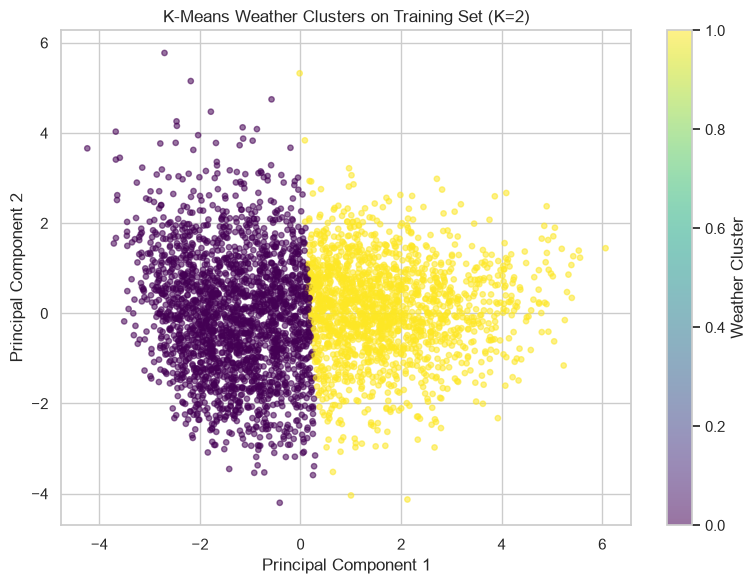

=== Weather Cluster Feature ===

Training cluster counts:
weather_cluster
0    2174
1    1659
Name: count, dtype: int64

Validation cluster counts:
weather_cluster
0    404
1    418
Name: count, dtype: int64

Test cluster counts:
weather_cluster
0    471
1    351
Name: count, dtype: int64

Updated feature count: 15
Training shape: (3833, 15)
Validation shape: (822, 15)
Test shape: (822, 15)


In [12]:
# Fit PCA on the standardized training data only
pca = PCA(n_components=2, random_state=42)

X_train_pca = pca.fit_transform(
    X_cluster_train_scaled
)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_.round(4)
)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# Plot training samples, colored by their K-Means cluster
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=train_clusters,
    cmap="viridis",
    alpha=0.55,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Weather Clusters on Training Set (K=2)")
plt.colorbar(label="Weather Cluster")
plt.tight_layout()
plt.show()



#  Check the results
print("=== Weather Cluster Feature ===")

print("\nTraining cluster counts:")
print(X_train["weather_cluster"].value_counts().sort_index())

print("\nValidation cluster counts:")
print(X_val["weather_cluster"].value_counts().sort_index())

print("\nTest cluster counts:")
print(X_test["weather_cluster"].value_counts().sort_index())

print("\nUpdated feature count:", X_train.shape[1])
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

In [13]:
#=============================================
#Training effect explore
#=============================================

In [14]:
# 1. Majority-class baseline
baseline_class = y_train.mode().iloc[0]

baseline_pred = np.full(
    len(y_val),
    baseline_class
)

print("=== Majority-Class Baseline ===")
print("Predicted class:", baseline_class)
print("Validation Accuracy:",
      round(accuracy_score(y_val, baseline_pred), 4))

=== Majority-Class Baseline ===
Predicted class: 1
Validation Accuracy: 0.573


## 3. Supervised Learning - Random Forest Classification

In [15]:
#========================
# Initial model training
#======================

In [16]:
if 0:
    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

# Fit the model using the training set only
    rf.fit(X_train, y_train)

# Predictions on the validation set
    y_val_pred = rf.predict(X_val)
    y_val_prob = rf.predict_proba(X_val)[:, 1]

# Validation Evaluation
    print("\n=== Random Forest Validation Results ===")

    print("Accuracy:",
          round(accuracy_score(y_val, y_val_pred), 4))

    print("Precision:",
          round(precision_score(
              y_val, y_val_pred, zero_division=0
          ), 4))

    print("Recall:",
          round(recall_score(
              y_val, y_val_pred, zero_division=0
          ), 4))

    print("F1-score:",
          round(f1_score(
              y_val, y_val_pred, zero_division=0
          ), 4))

    print("ROC-AUC:",
          round(roc_auc_score(y_val, y_val_prob), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        y_val_pred,
        target_names=["No Rain", "Rain Tomorrow"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_val_pred))

    # Feature Importance - Random Forest Built-in Method

    # Extract feature importance from the trained Random Forest
    importance_df = pd.DataFrame({
        "feature": X_train.columns,
        "importance": rf.feature_importances_
    })

    # Sort features by importance
    importance_df = importance_df.sort_values(
        by="importance",
        ascending=False
    )

    print("=== Random Forest Feature Importance ===")
    print(importance_df.round(4).to_string(index=False))

# Plot the top 10 features
    top10 = importance_df.head(10).sort_values(
        by="importance",
        ascending=True
    )

    plt.figure(figsize=(9, 6))
    plt.barh(
        top10["feature"],
        top10["importance"]
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Weather Feature")
    plt.title("Random Forest Feature Importance")
    plt.tight_layout()
    plt.show()

# ROC Curve - Random Forest Validation

# Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

# Calculate AUC
    roc_auc = roc_auc_score(y_val, y_val_prob)

# Plot
    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        label=f"Random Forest (AUC = {roc_auc:.3f})"
    )

# Reference line for random guessing
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve - Random Forest")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Validation ROC-AUC: {roc_auc:.4f}")

In [17]:
#==========================================================
# Random Forest Hyperparameter Comparison-can we improve it?
#===========================================================

In [18]:
if 1:
    rain_mask_train = (y_train == 1)
    X_train_rain = X_train[rain_mask_train]
    y_train_rain_amount = df_model.loc[X_train_rain.index, "precipitation_tomorrow"]

    param_grid_reg = {
        'n_estimators': [100, 200, 300],
        'max_depth': [6,8,10,15],       
        'min_samples_leaf': [10,20,50,100]
    }

    grid_search_reg = GridSearchCV(
        estimator=RandomForestRegressor(random_state=42),
        param_grid=param_grid_reg,
        cv=TimeSeriesSplit(n_splits=3),
        scoring='neg_mean_absolute_error', 
        n_jobs=-1,
        verbose=1
    )

    print("Conducting grid search...")
    grid_search_reg.fit(X_train_rain, y_train_rain_amount)

    print(f"Best hyperparameters: {grid_search_reg.best_params_}")
    print(f"Best MAE in test set: {-grid_search_reg.best_score_:.3f} mm")

#    best_rf_reg = grid_search_reg.best_estimator_

Conducting grid search...
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best hyperparameters: {'max_depth': 8, 'min_samples_leaf': 50, 'n_estimators': 100}
Best MAE in test set: 2.802 mm


In [19]:
if 1:
    param_grid = {
        'n_estimators': [100,200,300],
        'max_depth': [1, 2, 3, 4],
        'min_samples_leaf': [10, 20, 50, 100, 200]
    }

    grid_search = GridSearchCV(
        estimator=RandomForestClassifier(random_state=42,class_weight='balanced'),
        param_grid=param_grid,
        cv=TimeSeriesSplit(n_splits=3), 
        scoring='f1',
        n_jobs=-1,
        verbose=1
    )


    print("Conducting grid search...")
    grid_search.fit(X_train, y_train)


    print(f"Best hyperparameters: {grid_search.best_params_}")
    print(f"Highest F1 score in test set: {grid_search.best_score_:.4f}")


#    final_rf = grid_search.best_estimator_

Conducting grid search...
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Best hyperparameters: {'max_depth': 1, 'min_samples_leaf': 10, 'n_estimators': 300}
Highest F1 score in test set: 0.7197


In [20]:
# Final Model: Train on Training + Validation Sets

In [21]:
# 1. Combine training and validation sets
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# 2. Train the final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=1,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_val, y_train_val)

# 3. Predict on the untouched test set
y_test_pred = final_rf.predict(X_test)
y_test_prob = final_rf.predict_proba(X_test)[:, 1]

# 4. Evaluate final model
print("=== Final Random Forest: Test Results ===")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:",
      round(precision_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No Rain", "Rain Tomorrow"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))



=== Final Random Forest: Test Results ===
Accuracy: 0.7275
Precision: 0.7284
Recall: 0.8702
F1-score: 0.793
ROC-AUC: 0.7801

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.73      0.51      0.60       329
Rain Tomorrow       0.73      0.87      0.79       493

     accuracy                           0.73       822
    macro avg       0.73      0.69      0.70       822
 weighted avg       0.73      0.73      0.72       822

Confusion Matrix:
[[169 160]
 [ 64 429]]


In [22]:
#==================================
# Precipitation amount prediction
#==================================

In [23]:
rain_train_mask = (y_train_val == 1)
X_train_val_rain = X_train_val[rain_train_mask]
y_train_val_rain_amount = df_model.loc[X_train_val_rain.index, "precipitation_tomorrow"]

final_rf_reg = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)
final_rf_reg.fit(X_train_val_rain, y_train_val_rain_amount)


y_test_amount = df_model.loc[X_test.index, "precipitation_tomorrow"]
test_pred_amount = np.zeros(len(X_test))

rain_pred_indices = np.where(y_test_pred == 1)[0]
if len(rain_pred_indices) > 0:
    test_pred_amount[rain_pred_indices] = final_rf_reg.predict(X_test.iloc[rain_pred_indices])

mae = mean_absolute_error(y_test_amount, test_pred_amount)
rmse = root_mean_squared_error(y_test_amount, test_pred_amount)
print("=== Two-Stage Model Test Performance ===")
print(f"Overall Test MAE : {mae:.2f} mm")
print(f"Overall Test RMSE: {rmse:.2f} mm")


=== Two-Stage Model Test Performance ===
Overall Test MAE : 2.73 mm
Overall Test RMSE: 4.35 mm


In [24]:
# Output model
joblib.dump(final_rf_reg, "./models/final_rf_reg.joblib")
joblib.dump(final_rf, "./models/final_rf.joblib")
joblib.dump(scaler_cluster, "./models/scaler_cluster.joblib")
joblib.dump(kmeans, "./models/kmeans_weather.joblib")
print("Model saved successfully.")

Model saved successfully.


In [25]:
# ==============================================================================
# Final Model Visualization for binary prediction
# ==============================================================================

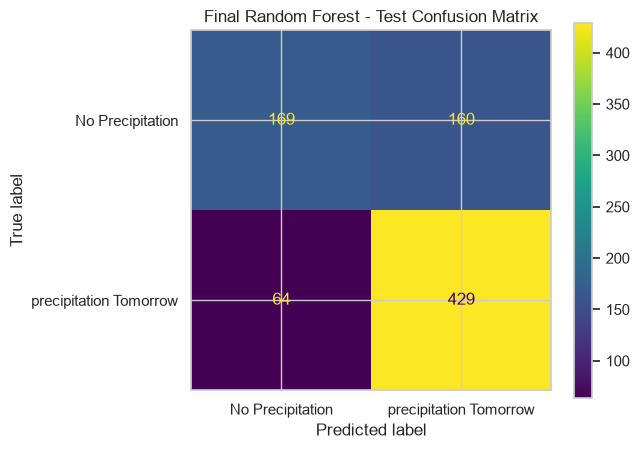

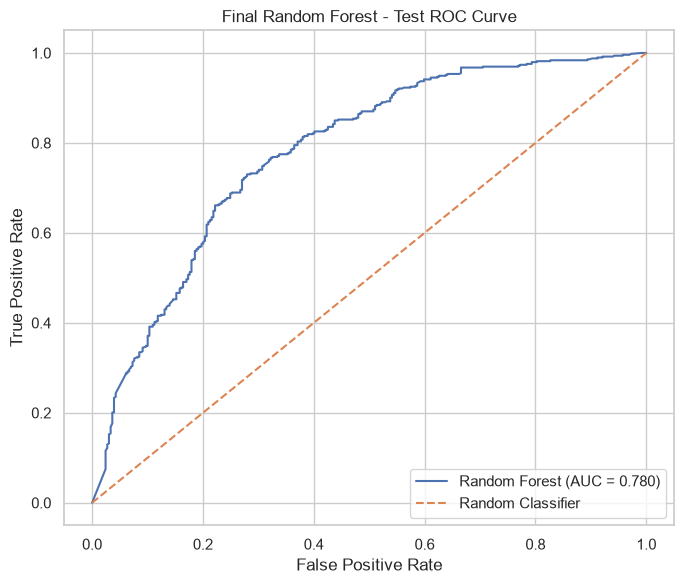

=== Final Model Feature Importance ===
            feature  importance
precipitation_today      0.2267
      pressure_mean      0.1633
   cloud_cover_mean      0.1267
     wind_speed_max      0.0967
    weather_cluster      0.0833
    pressure_change      0.0767
         temp_range      0.0667
      humidity_mean      0.0633
    dewpoint_spread      0.0467
      dewpoint_mean      0.0200
           temp_min      0.0200
          temp_mean      0.0100
           temp_max      0.0000
          month_cos      0.0000
          month_sin      0.0000


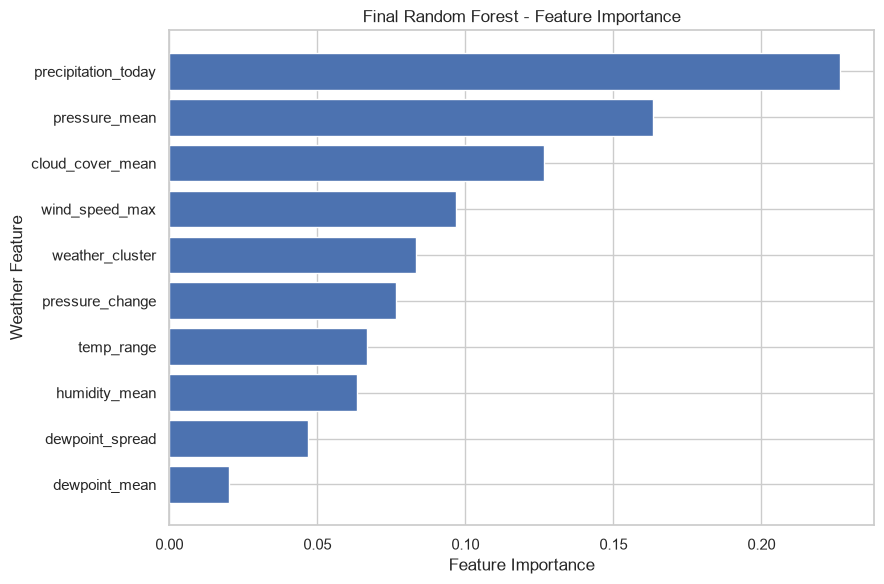


Final Test ROC-AUC: 0.7801


In [26]:
# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["No Precipitation", "precipitation Tomorrow"],
    values_format="d"
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("./outputs/test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. ROC Curve on the Test Set
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Random Forest - Test ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("./outputs/test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Feature Importance of the Final Model
importance_df = pd.DataFrame({
    "feature": X_train_val.columns,
    "importance": final_rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("=== Final Model Feature Importance ===")
print(importance_df.round(4).to_string(index=False))

top10 = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["feature"], top10["importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Final Random Forest - Feature Importance")
plt.tight_layout()
plt.savefig("./outputs/test_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nFinal Test ROC-AUC: {test_auc:.4f}")

In [27]:
#=============================================================
#Final Model Visualization for precipitation amount prediction
#==============================================================

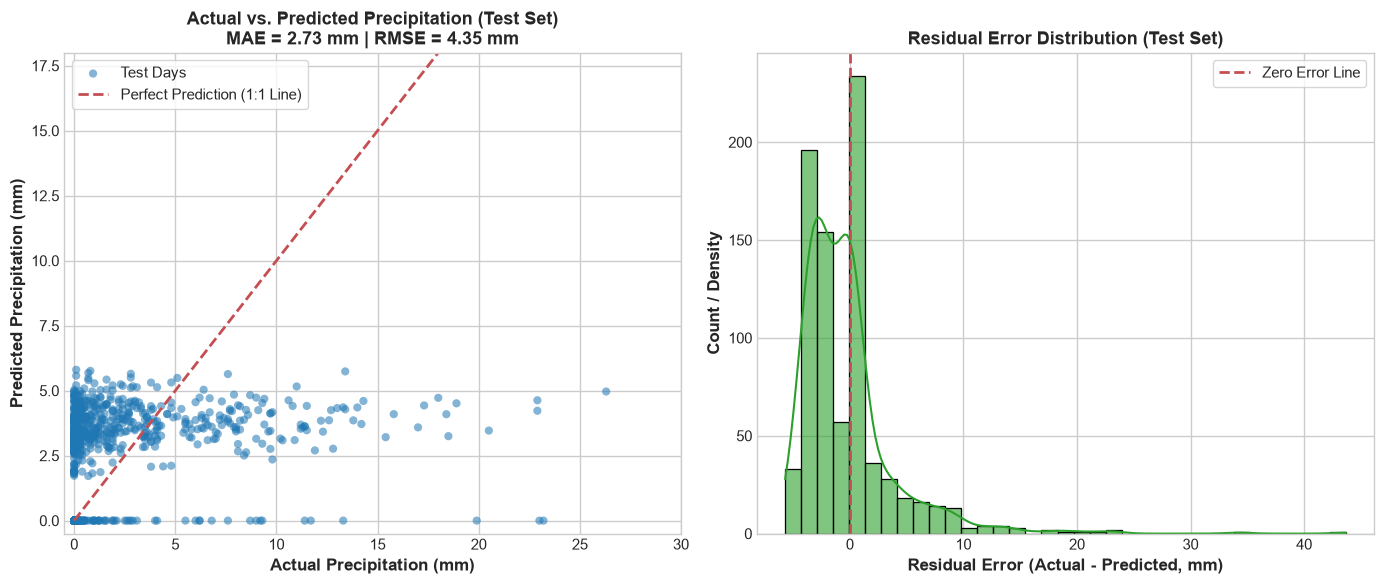

Final Test MAE : 2.726 mm
Final Test RMSE: 4.352 mm

=== Precipitation Amount Model (RF Regressor) Feature Importance ===
            feature  importance
      pressure_mean      0.1656
precipitation_today      0.1465
   cloud_cover_mean      0.1310
           temp_max      0.0890
      dewpoint_mean      0.0840
         temp_range      0.0661
    dewpoint_spread      0.0652
     wind_speed_max      0.0519
           temp_min      0.0516
          temp_mean      0.0400
    pressure_change      0.0377
      humidity_mean      0.0334
          month_sin      0.0209
          month_cos      0.0162
    weather_cluster      0.0008


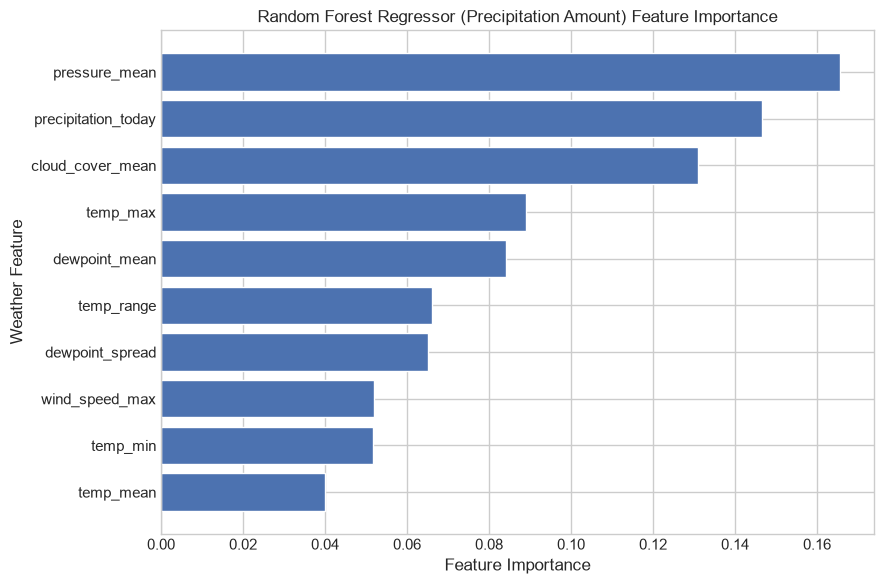

In [28]:
test_pred_class = final_rf.predict(X_test)
test_pred_amount = np.zeros(len(X_test))

rain_test_indices = np.where(test_pred_class == 1)[0]
if len(rain_test_indices) > 0:
    test_pred_amount[rain_test_indices] = final_rf_reg.predict(X_test.iloc[rain_test_indices])

y_test_amount = df_model.loc[X_test.index, "precipitation_tomorrow"]

# 3. residuals in test set
test_mae = mean_absolute_error(y_test_amount, test_pred_amount)
test_rmse = root_mean_squared_error(y_test_amount, test_pred_amount)
residuals_test = y_test_amount - test_pred_amount


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ---- fig 1:Actual vs. Predicted Precipitation ----
ax1.scatter(y_test_amount, test_pred_amount, alpha=0.55, color='#1f77b4', edgecolors='none', s=35, label='Test Days')
max_diag = 30
ax1.plot([0, max_diag], [0, max_diag], 'r--', lw=2, label='Perfect Prediction (1:1 Line)')
ax1.set_xlim(-0.5, 30)
ax1.set_ylim(-0.5, 18)
ax1.set_xlabel('Actual Precipitation (mm)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Predicted Precipitation (mm)', fontsize=12, fontweight='bold')
ax1.set_title(f'Actual vs. Predicted Precipitation (Test Set)\nMAE = {test_mae:.2f} mm | RMSE = {test_rmse:.2f} mm', fontsize=13, fontweight='bold')
ax1.legend(frameon=True, loc='upper left')

# ---- Fig 2: Residual Error Distribution----
sns.histplot(residuals_test, bins=35, kde=True, ax=ax2, color='#2ca02c', edgecolor='black', alpha=0.6)
ax2.axvline(0, color='r', linestyle='--', lw=2, label='Zero Error Line')
ax2.set_xlabel('Residual Error (Actual - Predicted, mm)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Count / Density', fontsize=12, fontweight='bold')
ax2.set_title('Residual Error Distribution (Test Set)', fontsize=13, fontweight='bold')
ax2.legend(frameon=True, loc='upper right')

plt.tight_layout()
plt.savefig('./outputs/test_regression_performance.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Final Test MAE : {test_mae:.3f} mm")
print(f"Final Test RMSE: {test_rmse:.3f} mm")

# ---- Fig 3: Fitures Rank----
importance_reg_df = pd.DataFrame({
    "feature": X_train_val_rain.columns,
    "importance": final_rf_reg.feature_importances_
}).sort_values(by="importance", ascending=False)

print("\n=== Precipitation Amount Model (RF Regressor) Feature Importance ===")
print(importance_reg_df.round(4).to_string(index=False))

top10_reg = importance_reg_df.head(10).sort_values(by="importance", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(top10_reg["feature"], top10_reg["importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Random Forest Regressor (Precipitation Amount) Feature Importance")
plt.tight_layout()
plt.savefig("./outputs/test_reg_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
#====================================================
# Model evaluation against persistence maseline model
#====================================================

In [30]:
test_pred_persistence_class = (
    df_model["precipitation_today"].iloc[val_end:] > 0.1
).astype(int)

# Directly predict precipitation the same as previous day
test_pred_persistence_amount = df_model["precipitation_today"].iloc[val_end:]

y_test_amount = df_model["precipitation_tomorrow"].iloc[val_end:]

print("=== Persistence Baseline: Test Results ===")
print("Accuracy :", round(accuracy_score(y_test, test_pred_persistence_class), 4))
print("Precision:", round(precision_score(y_test, test_pred_persistence_class, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, test_pred_persistence_class, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, test_pred_persistence_class, zero_division=0), 4))
print("MAE      :", round(mean_absolute_error(y_test_amount, test_pred_persistence_amount), 4), "mm")
print("RMSE     :", round(root_mean_squared_error(y_test_amount, test_pred_persistence_amount), 4), "mm")

=== Persistence Baseline: Test Results ===
Accuracy : 0.7178
Precision: 0.7647
Recall   : 0.7647
F1-score : 0.7647
MAE      : 3.1344 mm
RMSE     : 5.8242 mm


## 4. Neural Network Implementation

> The aim of this part is to develop a feedforward neural network to predict the next-day rainfall in Lund and compare it performance with the Random Forest classifier.

In [31]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler

### 4.1. Data Preperation

In [32]:
tf.keras.utils.set_random_seed(7)
scaler_nn = StandardScaler()

nn_features = [
    col for col in X_train.columns
    if col != "weather_cluster"  # binary feature
]

X_train_nn = scaler_nn.fit_transform(X_train[nn_features])
X_val_nn = scaler_nn.transform(X_val[nn_features])
X_test_nn = scaler_nn.transform(X_test[nn_features])

X_train_nn = np.column_stack([X_train_nn, X_train["weather_cluster"].to_numpy()])
X_val_nn = np.column_stack([X_val_nn, X_val["weather_cluster"].to_numpy()])
X_test_nn = np.column_stack([X_test_nn, X_test["weather_cluster"].to_numpy()])

print("Training:", X_train_nn.shape)
print("Validation:", X_val_nn.shape)
print("Test:", X_test_nn.shape)

Training: (3833, 15)
Validation: (822, 15)
Test: (822, 15)


### 4.2. Model Building

1. Input Layer (15 features)
2. Dense Layer - 64 neurons (ReLU activation), Dropout (0.2)
3. Dense Layer - 32 neurons (ReLU activation), Dropout (0.2)
4. Output Layer (Sigmoid activation)

In [33]:
num_features = X_train_nn.shape[1]

model = Sequential([
    Input(shape=(num_features,)),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3. Model Training

In [34]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn,
    y_train,

    validation_data=(X_val_nn, y_val),

    epochs=100,
    batch_size=32,

    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6288 - loss: 0.6425 - val_accuracy: 0.7165 - val_loss: 0.5668
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6741 - loss: 0.6087 - val_accuracy: 0.7214 - val_loss: 0.5589
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6848 - loss: 0.6035 - val_accuracy: 0.7214 - val_loss: 0.5597
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6861 - loss: 0.5984 - val_accuracy: 0.7238 - val_loss: 0.5573
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6906 - loss: 0.5958 - val_accuracy: 0.7190 - val_loss: 0.5571
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6924 - loss: 0.5917 - val_accuracy: 0.7190 - val_loss: 0.5563
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6919 - loss: 0.5907 - val_accuracy: 0.7190 - val_loss: 0.5575
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6908 - loss: 0.5886 - val_accu

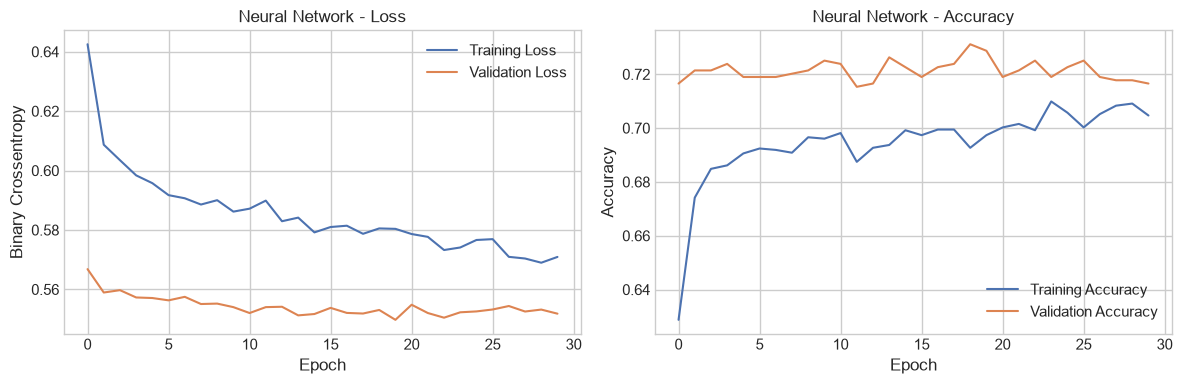

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")

axes[0].set_title("Neural Network - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

# Accuracy
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")

axes[1].set_title("Neural Network - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.4. Model Evaluation

In [36]:
def model_evaluation(y, y_prob, y_pred):
    accuracy_nn = accuracy_score(y, y_pred)
    precision_nn = precision_score(y, y_pred, zero_division=0)
    recall_nn = recall_score(y, y_pred, zero_division=0)
    f1_nn = f1_score(y, y_pred, zero_division=0)
    roc_auc_nn = roc_auc_score(y, y_prob)

    print(f"Accuracy: {accuracy_nn:.4f}")
    print(f"Precision: {precision_nn:.4f}")
    print(f"Recall: {recall_nn:.4f}")
    print(f"F1-score: {f1_nn:.4f}")
    print(f"ROC-AUC: {roc_auc_nn:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y,
        y_pred,
        target_names=["No Rain", "Rain Tomorrow"],
        zero_division=0
    ))

In [37]:
y_val_prob_nn = model.predict(X_val_nn).ravel()
y_val_pred_nn = (y_val_prob_nn >= 0.5).astype(int)

print("=== Neural Network Validation Results ===")
model_evaluation(y_val, y_val_prob_nn, y_val_pred_nn)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
=== Neural Network Validation Results ===
Accuracy: 0.7287
Precision: 0.7460
Recall: 0.7983
F1-score: 0.7713
ROC-AUC: 0.7894

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.70      0.64      0.67       351
Rain Tomorrow       0.75      0.80      0.77       471

     accuracy                           0.73       822
    macro avg       0.72      0.72      0.72       822
 weighted avg       0.73      0.73      0.73       822



In [38]:
y_test_prob_nn = model.predict(X_test_nn).ravel()
y_test_pred_nn = (y_test_prob_nn >= 0.5).astype(int)

print("=== Neural Network Test Results ===")
model_evaluation(y_test, y_test_prob_nn, y_test_pred_nn)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 905us/step
=== Neural Network Test Results ===
Accuracy: 0.7421
Precision: 0.7646
Recall: 0.8235
F1-score: 0.7930
ROC-AUC: 0.7751

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.70      0.62      0.66       329
Rain Tomorrow       0.76      0.82      0.79       493

     accuracy                           0.74       822
    macro avg       0.73      0.72      0.73       822
 weighted avg       0.74      0.74      0.74       822



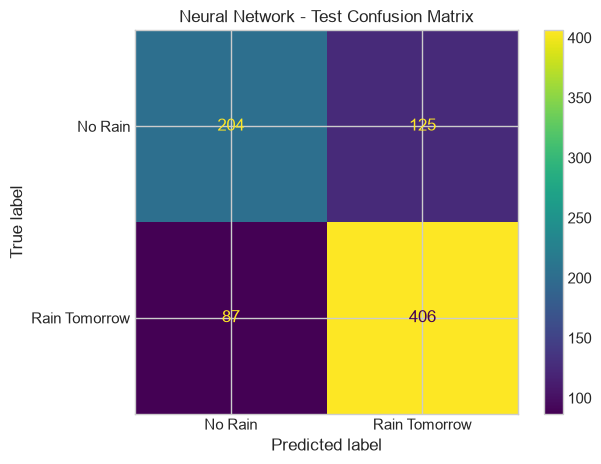

In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_nn,
    labels=[0, 1],
    display_labels=["No Rain", "Rain Tomorrow"],
    values_format="d"
)

plt.title("Neural Network - Test Confusion Matrix")
plt.tight_layout()
# plt.savefig("./outputs/test_confusion_matrix_nn.png", dpi=300, bbox_inches="tight")
plt.show()